In [ ]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.optimizers import Adam
import keras
from keras.models import Sequential, Model
from keras.layers import *
from keras.utils import Sequence
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

from keras.utils import Sequence
from keras.callbacks import CSVLogger
from keras.callbacks import EarlyStopping
from keras.losses import MeanSquaredError

import os
import random
from datetime import datetime
import time

import matplotlib.pyplot as plt

pi = 3.14159265359

maxval=1e9
minval=1e-9

2026-02-16 19:49:52.864603: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [ ]:
import importlib
import DAE_DataGenerator
import dataset_utils
import SoftQuantizeLayer
import AnnealingScheduler

importlib.reload(DAE_DataGenerator)
importlib.reload(dataset_utils)
importlib.reload(SoftQuantizeLayer)
importlib.reload(AnnealingScheduler)

from DAE_DataGenerator import OptimizedDataGenerator
from dataset_utils import add_noise, quantize_manual
#from dataprep import *
# from OptimizedDataGenerator_v2 import OptimizedDataGenerator
from loss import *


In [ ]:
dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = os.path.join(dataset_base_dir, "tfrecords")

dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'train/')
dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'test/')

tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train",'SQDAE_raw_80eN')
tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'SQDAE_raw_80eN')

# tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train",'3sr_16x16_80eN_raw')
# tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'3sr_16x16_80eN_raw')


print(dataset_dir_val)
batch_size = 5000
val_batch_size = 5000
train_file_size = 80
val_file_size = 20

In [4]:
start_time = time.time()
validation_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_val,
    file_type = "parquet",
    data_format = "3D",
    batch_size = val_batch_size,
    # optimize_batch_size = True,
    file_count = val_file_size,
    to_standardize= False,
    log_scale = False,
    select_contained = True,
    noise = [0,80], #[mean, sigma]
    # min_threshold = 400,
    # max_threshold = 1000,
    # charge_thresholds= [247.80, 668.41, 1662.85],
    charge_thresholds = None,
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, 
    files_from_end=True,

    tfrecords_dir = tfrecords_dir_val,
    use_time_stamps = [0,19],
    max_workers = 2
)
# validation_generator = [validation_generator[:][0], validation_generator[:][0]]

print("--- Validation generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 20/20 [00:07<00:00,  2.75it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_raw_80eN does not exist and cannot be removed.


Saving batches as TFRecords:   0%|          | 0/21 [00:00<?, ?it/s]2025-12-15 20:19:36.893487: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-12-15 20:19:36.923750: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-12-15 20:19:36.924111: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-12-15 20:19:36.925124: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To en

Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_raw_80eN/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_raw_80eN/metadata.json


--- Validation generator 19.772510051727295 seconds ---


In [6]:
print(validation_generator.dataset_logmax, validation_generator.dataset_logmin)

16.239303966535875 -11.77206435145071


2025-12-15 21:08:49.721471: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-12-15 21:08:50.793407: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-12-15 21:08:50.793954: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-12-15 21:08:50.796052: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropri

['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__iter__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_build_batching_plan', '_bytes_feature', '_keras_api_names', '_keras_api_names_v1', '_parse_tfrecord_fn', '_process_file_single', 'batch_metadata', 'batch_size', 'build_batch_metadata', 'charge_thresholds', 'dataset_logmax', 'dataset_logmin', 'dataset_max', 'dataset_mean', 'dataset_min', 'dataset_std', 'epoch_count', 'file_offsets', 'get_best_batch_size', 'input_shape', 'label_scale_pctl', 'labels_list', 'labels_scale', 'load_metadata', 'log_scale', 'max_threshold', 'min_threshold', 'noise', 'norm_factor_neg', 'norm_factor_pos', 'norm_neg_pctl', 'norm_pos_pctl', 'on_epoch_end', 'prepare_batch_data', 'process_

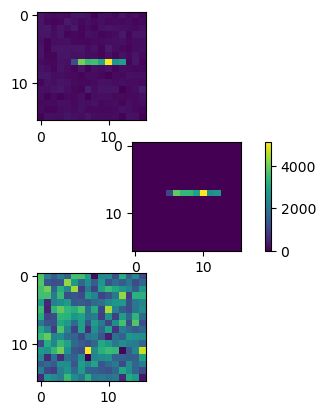

In [5]:
# print(type(validation_generator), len(validation_generator))
# validation_generator = [validation_generator[:][0], validation_generator[:][0]]
# print(type(validation_generator), len(validation_generator))

fig, ax = plt.subplots(3,1)
batch_index = 0
N = 28
ts = 1

X_in = training_generator[batch_index][0][N]
X_out = training_generator[batch_index][1][N]


# val_max = training_generator.max
print(dir(training_generator))
def get_min_max(training_generator, validation_generator):
    tmax,tmin = [training_generator.dataset_max, training_generator.dataset_min]
    vmax,vmin = [validation_generator.dataset_max, validation_generator.dataset_min]
    return min(tmin, vmin), max(tmax, vmax)
# print(training_generator.dataset_max, training_generator.dataset_min)
# print(validation_generator.dataset_max, validation_generator.dataset_min)
print(get_min_max(training_generator, validation_generator))
print(training_generator[N][1].shape, training_generator[batch_index][1][N].dtype)
# X_in = validation_generator[batch_index][0][N]
# X_out = validation_generator[batch_index][1][N]

ax[0].imshow(X_in[:,:,ts]) 
a = ax[1].imshow(X_out[:,:,ts]) 
ax[2].imshow((X_in-X_out)[:,:,ts]) 
# print(X_in[:,:,ts])
print(type(X_in))
#indicies: batch_index, in/out, index_in_batch, {nxm pixels}, time slice
# ax[1].imshow(validation_generator[1][11][:,:,1])

fig.colorbar(a)


In [10]:
# training generator
start_time = time.time()
training_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_train,
    file_type = "parquet",
    data_format = "3D",
    batch_size = batch_size,
    # optimize_batch_size = True,
    file_count = train_file_size,
    to_standardize= False,
    select_contained = True,
    log_scale = False,
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, # True 
    noise = [0,80],
    # charge_thresholds= [247.80, 668.41, 1662.85],
    charge_thresholds = None,

    # threshold = 400,
    tfrecords_dir = tfrecords_dir_train,
    use_time_stamps = [0,19],
    max_workers = 2
)

# training_generator = [training_generator[:][0], training_generator[:][0]]

print("--- Training generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 80/80 [00:21<00:00,  3.71it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_raw_80eN is removed...


Saving batches as TFRecords: 100%|██████████| 84/84 [00:45<00:00,  1.85it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_raw_80eN/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_raw_80eN/metadata.json
--- Training generator 67.84706401824951 seconds ---


In [4]:
# Loading pre-generated TFRecords
validation_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir= tfrecords_dir_val,
    shuffle=False,
    # seed=42,
    quantize=False,
)

training_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir = tfrecords_dir_train,
    shuffle=False,
    # seed=42,
    quantize=False,
)

Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/SQDAE_raw_80eN/metadata.json


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/SQDAE_raw_80eN/metadata.json


In [7]:
import models
importlib.reload(models)
from models import CreateAutoEncoder
from SoftQuantizeLayer import SoftQuantizeLayer
from AnnealingScheduler import AnnealingScheduler

def encoder_network(shape, var, kernel_size=3, n_filters=5, pool_size=2):
    var = QSeparableConv2D(
        n_filters, kernel_size, padding = 'same',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)
    var = AveragePooling2D(
        pool_size=(pool_size, pool_size), 
        strides=pool_size, 
        padding="same", 
        data_format='channels_last',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)
    var = QConv2D(
        n_filters,kernel_size, padding = 'same',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)  
    var = AveragePooling2D(
        pool_size=(pool_size, pool_size), 
        strides=pool_size, 
        padding="same", 
        data_format='channels_last',
    )(var)
    var = QActivation("quantized_tanh(4, 0, 1)")(var)  
    return var

def decoder_network(shape, var, kernel_size=3, n_filters=5, pool_size=2):
    var = Conv2DTranspose(
        n_filters, 1, padding = 'same', strides = pool_size,
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    var = Conv2DTranspose(
        n_filters, kernel_size,
        strides = pool_size,
        padding="same",
    )(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)    
    var = Conv2D(shape[-1], (pool_size, pool_size), padding="same")(var)
    var = QActivation("quantized_tanh(16, 0, 1)")(var)
    # if input_quant is not None:
    #     # quantize = lambda x: quantize_manual(x, charge_levels = input_quant, quant_values =[0,1,2,3])
    #     quantize = lambda x: hard_quantize(x, levels = [0.0,1.0,2.0,3.0], thresholds = input_quant)
    #     var = Lambda(function=quantize, dtype=tf.float32)(var)
    return var

def get_min_max(training_generator, validation_generator, logrange=True):
    if logrange:
        tmax,tmin = [training_generator.dataset_logmax, training_generator.dataset_logmin]
        vmax,vmin = [validation_generator.dataset_logmax, validation_generator.dataset_logmin]
    else:
        tmax,tmin = [training_generator.dataset_max, training_generator.dataset_min]
        vmax,vmin = [validation_generator.dataset_max, validation_generator.dataset_min]
    return np.float32(min(tmin, vmin)), np.float32(max(tmax, vmax))

def CreateSQAutoEncoder(shape, n_filters=5, pool_size=2, conv_kernel_size=3, decoder_filters = 5, mean_filter=False, thresh = False, xrange = [-1,1], log_standardize=True):
    x_base = x_in = Input(shape)
    x_base = SoftQuantizeLayer(
        n_bits=2,
        initial_thresholds = [247.80, 668.41, 1662.85],
        # initial_levels = [0.0, 0.33333, 0.66667, 1.0],
        initial_levels = [0.0, 1.0, 2.0, 3.0],
        threshold_offset = 80.0,
        # initial_range=[-1.0, 1.0],
        trainable_levels=False,
        trainable_thresholds=True,
        initial_k=1.0,
        trainable_k=True,
        name='soft_quantizer_output'
    )(x_base)
    stack = encoder_network(shape, x_base, n_filters=n_filters, pool_size=pool_size, kernel_size = conv_kernel_size)
    stack = decoder_network(shape, stack, n_filters=decoder_filters, pool_size=pool_size, kernel_size = conv_kernel_size)
    # print(type(stack))
    if xrange is not None:
        def scaled_function(data):
            return asymmetric_scaling(data, pos_scale=xrange[1], neg_scale=abs(xrange[0]))
        stack = Lambda(function = scaled_function)(stack)
    model = Model(inputs=x_in, outputs=stack)
    return model

In [8]:
import loss
importlib.reload(loss)
from loss import CustomSSIMClass, CustomSSIM
xrange = get_min_max(training_generator, validation_generator, logrange=True)

model=CreateSQAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3, 
                        decoder_filters = 128, 
                        # input_quant = [0.2,0.6,3.0],
                        xrange = None
                       )
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    # loss=MeanSquaredError()
    # loss=CustomSSIMClass(xrange = xrange, log_standardize = False),
    loss=CustomSSIM(logxrange = xrange, log_standardize = True)
    # run_eagerly=True
)

model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 soft_quantizer_output (Soft  (None, 16, 16, 2)        4         
 QuantizeLayer)                                                  
                                                                 
 q_separable_conv2d (QSepara  (None, 16, 16, 5)        33        
 bleConv2D)                                                      
                                                                 
 q_activation (QActivation)  (None, 16, 16, 5)         0         
                                                                 
 average_pooling2d (AverageP  (None, 8, 8, 5)          0         
 ooling2D)                                                       
                                                             

In [9]:
from datetime import datetime
tname = 'SQDAE_2bit_80eN_SSIM_LogScaled_QRange0to3_80eThreshOffset'
fingerprint = '%08x' % random.randrange(16**8)
timestamp = datetime.now().strftime('%Y%m%d-%H%M%S')
os.makedirs("trained_models", exist_ok=True)
base_dir = f'./SQ_DAE/model-{fingerprint}-{tname}-checkpoints'
os.makedirs(base_dir, exist_ok=True)  
checkpoint_filepath = base_dir + '/weights.{epoch:02d}-t{loss:.4f}-v{val_loss:.4f}.hdf5'
print("fingerprint: ", fingerprint)

fingerprint:  e12251df


In [10]:
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, Callback
import csv

early_stopping_patience = 200

class CustomModelCheckpoint(ModelCheckpoint):
    def on_epoch_end(self, epoch, logs=None):
        super().on_epoch_end(epoch, logs)
        checkpoints = [f for f in os.listdir(base_dir) if f.startswith('weights')]
        if len(checkpoints) > 1:
            checkpoints.sort(key=lambda x: os.path.getmtime(os.path.join(base_dir,x)))
            for checkpoint in checkpoints[:-1]:
                os.remove(os.path.join(base_dir, checkpoint))

class SoftQuantizeLoggerCallback(Callback):
    def __init__(self, log_filepath, layer_name="soft_quantizer_output"):
        super().__init__()
        self.log_filepath = log_filepath
        self.layer_name = layer_name
        self.header_written = False

    def on_train_begin(self, logs=None):
        os.makedirs(os.path.dirname(self.log_filepath), exist_ok=True)

    def on_epoch_end(self, epoch, logs=None):
        try:
            layer = self.model.get_layer(self.layer_name)
            if not hasattr(layer, 'n_bits'):
                 print(f"\nWarning: Layer '{self.layer_name}' is not a SoftQuantizeLayer. Skipping logging.")
                 return
        except ValueError:
            print(f"\nWarning: Layer '{self.layer_name}' not found in the model. Skipping logging.")
            return

        if not self.header_written:
            num_levels = layer.num_levels
            num_thresholds = num_levels - 1
            
            header = ['epoch', 'k']
            header.extend([f'level_{i}' for i in range(num_levels)])
            header.extend([f'threshold_{i}' for i in range(num_thresholds)])

            header.append('raw_first_level')
            header.extend([f'raw_log_level_delta_{i}' for i in range(num_levels - 1)])
            header.append('raw_first_threshold')
            if hasattr(layer, 'log_threshold_deltas'):
                header.extend([f'raw_log_threshold_delta_{i}' for i in range(num_thresholds - 1)])

            with open(self.log_filepath, mode='w', newline='') as f:
                writer = csv.writer(f)
                writer.writerow(header)
            self.header_written = True

        k_val = layer.k.numpy().item()
        levels = layer.levels.numpy().tolist()
        thresholds = layer.thresholds.numpy().tolist()
        
        # first_level = layer.first_level.numpy().item()
        # log_level_deltas = layer.log_level_deltas.numpy().tolist()
        # first_threshold = layer.first_threshold.numpy().item()
        
        row_data = [epoch, k_val]
        row_data.extend(levels)
        row_data.extend(thresholds)
        # row_data.append(first_level)
        # row_data.extend(log_level_deltas)
        # row_data.append(first_threshold)
        
        if hasattr(layer, 'log_threshold_deltas'):
            log_threshold_deltas = layer.log_threshold_deltas.numpy().tolist()
            row_data.extend(log_threshold_deltas)
        
        with open(self.log_filepath, mode='a', newline='') as f:
            writer = csv.writer(f)
            writer.writerow(row_data)


csv_logger = CSVLogger(f'{base_dir}/training_log.csv', append=True)
scheduler_callback = AnnealingScheduler(
    schedule='cosine',  
    target_layer_name='soft_quantizer_output', 
    initial_k=1.0,
    final_k=67.0, 
    verbose=1      
)

quantizer_logger = SoftQuantizeLoggerCallback(
    log_filepath=f"{base_dir}/soft_quantizer_state_log.csv", # New, more descriptive filename
    layer_name="soft_quantizer_output"
)

es = EarlyStopping(patience=early_stopping_patience, restore_best_weights=True)

mcp = CustomModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    save_best_only=True,
    save_freq='epoch',
    verbose=1
)


In [11]:
history = model.fit(
        x=training_generator,
        validation_data=validation_generator,
        callbacks=[es, mcp, csv_logger,scheduler_callback, quantizer_logger],
        epochs=1000,
        shuffle=False,
        verbose=1
    )


Epoch 1: Annealing 'k' set to 1.0000
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 247.8000, 668.4100, 1662.8501
	Tau: [294.20502 707.525   994.44006]
Epoch 1/1000


2025-12-15 21:10:38.105881: I tensorflow/stream_executor/cuda/cuda_blas.cc:1614] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2025-12-15 21:10:38.241054: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8800


84/84 [==============================] - ETA: 0s - loss: 0.3464
Epoch 1: val_loss improved from inf to 0.29999, saving model to ./SQ_DAE/model-e12251df-SQDAE_2bit_80eN_SSIM_LogScaled_QRange0to3_80eThreshOffset-checkpoints/weights.01-t0.3464-v0.3000.hdf5
84/84 [==============================] - 91s 908ms/step - loss: 0.3464 - val_loss: 0.3000

Epoch 2: Annealing 'k' set to 1.0002
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 249.2500, 673.6833, 1676.7295
	Tau: [ 296.84167  713.73975 1003.04614]
Epoch 2/1000
84/84 [==============================] - ETA: 0s - loss: 0.2856
Epoch 2: val_loss improved from 0.29999 to 0.27426, saving model to ./SQ_DAE/model-e12251df-SQDAE_2bit_80eN_SSIM_LogScaled_QRange0to3_80eThreshOffset-checkpoints/weights.02-t0.2856-v0.2743.hdf5
84/84 [==============================] - 14s 164ms/step - loss: 0.2856 - val_loss: 0.2743

Epoch 3: Annealing 'k' set to 1.0007
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 249.6617, 675.2864, 1680.8910
	Tau: [ 297.

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



84/84 [==============================] - ETA: 0s - loss: 0.1349
Epoch 675: val_loss did not improve from 0.13507
84/84 [==============================] - 13s 159ms/step - loss: 0.1349 - val_loss: 0.1351

Epoch 676: Annealing 'k' set to 51.2425
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 80.3133, 272.4177, 499.6673
	Tau: [ 96.208824 209.677    227.24963 ]
Epoch 676/1000
84/84 [==============================] - ETA: 0s - loss: 0.1349
Epoch 676: val_loss did not improve from 0.13507
84/84 [==============================] - 13s 153ms/step - loss: 0.1349 - val_loss: 0.1352

Epoch 677: Annealing 'k' set to 51.3308
	Levels: 0.0000, 1.0000, 2.0000, 3.0000
	Thresholds: 80.3133, 273.1262, 499.7534
	Tau: [ 96.5631  209.72006 226.62718]
Epoch 677/1000
84/84 [==============================] - ETA: 0s - loss: 0.1349
Epoch 677: val_loss did not improve from 0.13507
84/84 [==============================] - 13s 157ms/step - loss: 0.1349 - val_loss: 0.1353

Epoch 678: Annealing 'k' set to 51.41

In [ ]:
'''Load weights and extract the encoder'''

import models
importlib.reload(models)
from models import CreateAutoEncoder

weights_path = './trained_models/DAE/model-e4177e22-DAE_80eNoise_5filters_convTranspose-checkpoints'
base_dir = weights_path
checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
#training_cp_path = os.path.join(base_dir, 'training_log.csv')
#training_history = pd.read_csv(training_cp_path)

print(f"Loading model from {latest_checkpoint}")
DAE=CreateAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3)
DAE.load_weights(latest_checkpoint)
model_summary = [[layer.name, layer.output.shape] for layer in DAE.layers]

# for layer in DAE.layers:
#     print(layer.name)

layer_name = DAE.layers[8].name 
# print(layer_name)
encoder = Model(inputs=DAE.input, outputs=DAE.get_layer(layer_name).output)
encoder.trainable = False
encoder.summary()

print(encoder.output.shape)



In [ ]:
'''attach a dense regression network to the latent space'''
from models import var_network

x_in = encoder.input
lat_shape = encoder.output.shape
dense = var_network(encoder.output, hidden=16, output=14)
model = Model(inputs=x_in, outputs=dense)

model.summary()